In [2]:
import pandas as pd
import numpy as np

data = pd.read_csv('fer2013.csv', on_bad_lines='skip')

train_data = data[data['Usage'] == 'Training']
X_train = np.array([np.fromstring(x, dtype=np.uint8, sep=' ') for x in train_data['pixels']]).reshape(-1, 48, 48)
y_train = train_data['emotion'].values

validation_data = data[data['Usage'] == 'PublicTest']
X_validation = np.array([np.fromstring(x, dtype=np.uint8, sep=' ') for x in validation_data['pixels']]).reshape(-1, 48, 48)
y_validation = validation_data['emotion'].values

test_data = data[data['Usage'] == 'PrivateTest']
X_test = np.array([np.fromstring(x, dtype=np.uint8, sep=' ') for x in test_data['pixels']]).reshape(-1, 48, 48)
y_test = test_data['emotion'].values

print(f"Training shapes: {X_train.shape}, {y_train.shape}")
print(f"Validation shapes: {X_validation.shape}, {y_validation.shape}")
print(f"Testing shapes: {X_test.shape}, {y_test.shape}")

print(f"Total rows loaded: {len(data)}")

Training shapes: (28709, 48, 48), (28709,)
Validation shapes: (3589, 48, 48), (3589,)
Testing shapes: (3589, 48, 48), (3589,)
Total rows loaded: 35887


In [15]:
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using Device: {device}")

class FERDataset(Dataset):

  def __init__(self, images, labels):
    self.images = torch.tensor(images, dtype=torch.float32).unsqueeze(1) / 255.0
    self.labels = torch.tensor(labels, dtype=torch.long)

  def __len__(self):
    return len(self.images)

  def __getitem__(self, index):
    return self.images[index], self.labels[index]


train_dataset = FERDataset(X_train, y_train)
val_dataset = FERDataset(X_validation, y_validation)
test_dataset = FERDataset(X_test, y_test)

batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)


class EmotionCNN(nn.Module):

  def __init__(self):
    super(EmotionCNN, self).__init__()

    self.conv1 = nn.Conv2d(1, 64, kernel_size=3, padding=1)
    self.bn1 = nn.BatchNorm2d(64)
    self.pool1 = nn.MaxPool2d(2, 2)

    self.conv2 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
    self.bn2 = nn.BatchNorm2d(128)
    self.pool2 = nn.MaxPool2d(2, 2)

    self.conv3 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
    self.bn3 = nn.BatchNorm2d(256)
    self.pool3 = nn.MaxPool2d(2, 2)

    self.fc1 = nn.Linear(256 * 6 * 6, 512)
    self.dropout = nn.Dropout(0.5)
    self.fc2 = nn.Linear(512, 7)

  def forward(self, x):
    x = self.pool1(torch.relu(self.bn1(self.conv1(x))))
    x = self.pool2(torch.relu(self.bn2(self.conv2(x))))
    x = self.pool3(torch.relu(self.bn3(self.conv3(x))))

    x = x.view(x.size(0), -1)
    x = self.dropout(torch.relu(self.fc1(x)))
    x = self.fc2(x)
    return x


model = EmotionCNN().to(device)




Using Device: cuda


In [21]:
import torch.optim as optim
import time

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

epochs = 30
best_val_accuracy = 0.0

print("Starting Training Loop...\n")

history = {
    'epoch': [],
    'train_loss': [],
    'val_loss': [],
    'train_acc': [],
    'val_acc': []
}

for epoch in range(epochs):
  start_time = time.time()
  model.train()
  train_loss = 0.0
  correct_train = 0
  total_train = 0

  for images, labels in train_loader:
    images, labels = images.to(device), labels.to(device)
    optimizer.zero_grad()
    outputs = model(images)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()
    train_loss += loss.item()
    _, predicted = torch.max(outputs.data, 1)
    total_train += labels.size(0)
    correct_train += (predicted == labels).sum().item()

  train_accuracy = 100 * correct_train / total_train
  avg_train_loss = train_loss / len(train_loader)

  model.eval()
  val_loss = 0.0
  correct_val = 0
  total_val = 0

  with torch.no_grad():
    for images, labels in val_loader:
      images, labels = images.to(device), labels.to(device)
      outputs = model(images)
      loss = criterion(outputs, labels)

      val_loss += loss.item()
      _, predicted = torch.max(outputs.data, 1)
      total_val += labels.size(0)
      correct_val += (predicted == labels).sum().item()


  val_accuracy = 100 * correct_val / total_val
  avg_val_loss = val_loss / len(val_loader)

  epoch_time = time.time() - start_time

  print(f"Epoch [{epoch+1}/{epochs}] | Time: {epoch_time:.0f}s")
  print(f"Train Loss: {avg_train_loss:.4f} | Train Acc: {train_accuracy:.2f}%")
  print(f"Val Loss:   {avg_val_loss:.4f} | Val Acc:   {val_accuracy:.2f}%")

  if val_accuracy > best_val_accuracy:
    best_val_accuracy = val_accuracy
    torch.save(model.state_dict(), 'best_emotion_model.pth')
    print(f"🌟 Saved New Best Model! (Acc: {val_accuracy:.2f}%)")

  history['epoch'].append(epoch + 1)
  history['train_loss'].append(avg_train_loss)
  history['val_loss'].append(avg_val_loss)
  history['train_acc'].append(train_accuracy)
  history['val_acc'].append(val_accuracy)

  print("-" * 50)

print("Training Complete! The best weights are saved in 'best_emotion_model.pth'")

Starting Training Loop...

Epoch [1/30] | Time: 7s
Train Loss: 0.2559 | Train Acc: 90.97%
Val Loss:   2.0980 | Val Acc:   57.95%
🌟 Saved New Best Model! (Acc: 57.95%)
--------------------------------------------------
Epoch [2/30] | Time: 7s
Train Loss: 0.2525 | Train Acc: 91.03%
Val Loss:   2.2017 | Val Acc:   58.29%
🌟 Saved New Best Model! (Acc: 58.29%)
--------------------------------------------------
Epoch [3/30] | Time: 7s
Train Loss: 0.2321 | Train Acc: 91.74%
Val Loss:   2.0925 | Val Acc:   57.48%
--------------------------------------------------
Epoch [4/30] | Time: 7s
Train Loss: 0.2249 | Train Acc: 92.38%
Val Loss:   2.1389 | Val Acc:   59.38%
🌟 Saved New Best Model! (Acc: 59.38%)
--------------------------------------------------
Epoch [5/30] | Time: 7s
Train Loss: 0.2036 | Train Acc: 92.80%
Val Loss:   1.9696 | Val Acc:   58.32%
--------------------------------------------------
Epoch [6/30] | Time: 7s
Train Loss: 0.2133 | Train Acc: 92.51%
Val Loss:   2.1218 | Val Acc:  

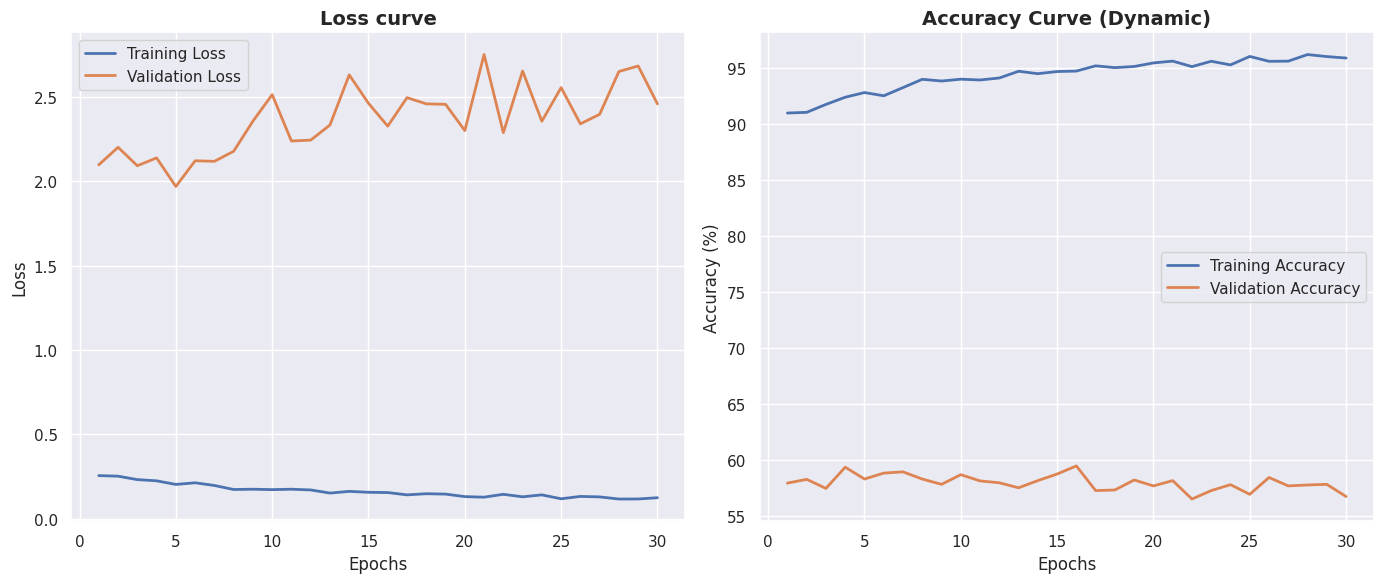

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame(history)

df.to_csv('training_history.csv', index=False)

sns.set_theme(style='darkgrid')
plt.figure(figsize=(14,6))

plt.subplot(1, 2, 1)
sns.lineplot(data=df, x='epoch', y='train_loss', label='Training Loss', linewidth=2)
sns.lineplot(data=df, x='epoch', y='val_loss', label='Validation Loss', linewidth=2)
plt.title('Loss curve', fontsize=14, fontweight='bold')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.subplot(1, 2, 2)
sns.lineplot(data=df, x='epoch', y='train_acc', label='Training Accuracy', linewidth=2)
sns.lineplot(data=df, x='epoch', y='val_acc', label='Validation Accuracy', linewidth=2)
plt.title('Accuracy Curve (Dynamic)', fontsize=14, fontweight='bold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')

plt.tight_layout()
plt.show()